# Introduction to Probability Distributions

In this activity, you will explore probability distributions using the Maxwell Speed Distribution! Probability distributions are important in multiple areas of physical chemistry, so it's helpful to understand the basics of visualizing and characterizing probability distributions!

In order for you to be able to visualize and characterize probability distributions on your own, this activity will also cover some new Python skills, including using the numpy, scipy, and matplotlib libraries!

# Import the relevant python libraries 

In [6]:
# Import the scientific python (scipy) and numerical python (numpy) libraries
# Import a library for making plots from matplotlib
import scipy
import numpy as np
import matplotlib.pyplot as plt

<h2 style="color:Red;">INSTRUCTOR NOTES</h2>
<h2 style="color:Red;">***</h2>
I typically give a lecture on Probability Distributions the class prior to running this activty just so that the students are already familiar with the background information provided here. Depending on students' level of familiarity with probability distributions, that might not be necessary. 
<h2 style="color:Red;">***</h2>

# Background Information on Probability Distributions
The probability distribution function, $P(x)$, is the probability of a variable $x$ having a given outcome, written as a function of that variable $x$.
The probability distribution function $P(x)$ is equal to the value of the probability function for that outcome, $f(x)$,
divided by the total probability for all possible outcomes, $P_{Total}$.
$$
P(x) = \frac{f(x)}{P_{Total}}
$$
The recipricol of the total probability for all possible outcomes is called the normalization constant. Multiplying by the normalization constant (i.e., dividing by the total probability) ensures that the total probability is equal to 1, that is, to 100%.

### Example

Consider rolling a fair, six-sided die. There's a "one in six" chance of rolling the number five. Why?

Well, the probability of rolling a number five is the probability function for that outcome, and we can set that equal to one: $f(5)=1$. In order to convert this function to actual probability distirbution function, we need to divide by the total probability. The total probability is the sum of the probabilities for all the possible outcomes we could get:
$$
\begin{aligned}
P_{total} &= f(1)+f(2)+f(3)+f(4)+f(5)+f(6) \\
&= 1+1+1+1+1+1\\
&=6
\end{aligned}
$$

So then the value of the probability distribution function would be:
$$
P(5) = \frac{f(5)}{P_{Total}} = \frac{1}{6}
$$

## For a Discrete Variable
It's only possible to get specific $x$ values when the variable is discrete. The probability of getting a specific value $x_i$ is given by $f(x_i),$ and the total probability is the sum of all these individual probabilities, $\sum_i f(x_i)$.

The probability distribution function, which gives the actual probability of getting any of the specific $x$ values is given by:
$$
P(x_i) = \frac{f(x_i)}{\sum_j f(x_j)}
$$

You can write out this sum for the example of rolling a die above:
$$
P(5) = \frac{f(5)}{\sum_j f(j)} = \frac{f(5)}{f(1)+f(2)+f(3)+f(4)+f(5)+f(6)} =\frac{1}{1+1+1+1+1+1} = \frac{1}{6}
$$

## For a Continuous Variable
It's possible to get any $x$ value when the variable is continuous. The probability of getting the value $x$ is given by a continuous function $f(x),$ and the total probability is the integral of that function over the full "domain" of $x$ (i.e., the sample space), $\int_{-\infty}^{\infty}f(x)dx$, where the default "domain" is $-\infty$ to $\infty$, but it could be something else, like $0$ to $\infty$, e.g., if $x$ refers to a radius. Integrating over all the probabilities for a continuous variable is like adding up all the probabilities for a discrete variable.

The probabiilty distribution function, which gives the actual probability of getting any $x$ value is given by:
$$
P(x) = \frac{f(x)}{\int_{-\infty}^{\infty}f(x)dx}
$$

Now after reviewing that background on probability distributions, let's move onto exploring what we can learn from them!

# New Python Skill: Defining Functions
In the Introduction to Programming for Molecular Scientists module, we learned how to use built-in functions from the Python libraries that we loaded. But that's not the only way to use a function! You can define your own functions!

A function is defined by using the `def` keyword, then providing the name of the function, with all the arguments to that function provided in parentheses. Then within the function, variables can be assigned and tasks can be carried out. Finally, the function includes a `return` keyword, which tells the computer what should be outcome of calling the function.
```
def function_name(arg1, arg2, arg3, arg4, ...):
    definitions and tasks ...
    return value
```
The arguments are the variables for the function, which is intuitive if we are just defining mathematical functions to use. However, sometimes you want the user to be able to change or select some parameter when calling the function, even if that parameter is not typically considered a variable in the function. As a result, the arguments that you set in the function definition should correspond to any value or parameter that you want the user to be able to select when calling the function.



<h2 style="color:Red;">INSTRUCTOR NOTES</h2>
<h2 style="color:Red;">***</h2>
Sometimes my students have had trouble understanding how functions in python work, so I make certain to relate the functions back to the simple f(x) from math, and I also mention here that it's ok if they get confused because it's a different way of thinking of functions than they might be used to in math. It's anecdotal, but I think some of the less confident students benefit from that extra bit of encouragement because then they feel comfortable asking me questions about functions later. 
<h2 style="color:Red;">***</h2>

In [5]:
# Let's define the function: f(x)=2x 
# We will give it the name double(x) instead of f(x) here so that the function name tells us what it does.

def double(x):
  factor=2
  return x*factor

In [ ]:
# Try out your new function for x=5
double(5)

10

In [ ]:
# You could also set your function equal to a variable, and use that variable later on.
double_five = double(5)
print(double_five)

10


You also might consider that you could change the multiplicative factor in your function. What if you want to multiple $x$ by 3 instead of by 2? You can define a function with mulitple arguments as well.

In [16]:
# Let's define the function: f(x,a)=a*x 
# We will give it the name times_a(x,a) instead of f(x,a) here so that the function name tells us what it does.

def times_a(x,a):
  factor=a
  return x*factor

In [24]:
# Now try it out for a few different combinations of a and x
print(times_a(5,2))
print(times_a(5,3))
x=2
a=3
print(times_a(x,a))
print(times_a(3,10))

10
15
6
30


Great! Now we can define a function of our own...but WAIT! Why do the last couple lines of code in the previous cell work? How can you set variables called $x$ and $a$, when those are the names of the arguments you used to define the function? 

## Global vs Local Variables
* A "global" variable is defined outside of functions and is accessible anywhere in the jupyter notebook.
* A "local" variable is only defined within a function and is only accessible within that function - it's not accessible outside of the function. In fact, it only exists when that function is called, otherwise, it's not defined.

Understanding the difference between global and local variables is confusing because many people name their global and local variables the same name, as was done in the last few lines of the previous codeblock.

First, let's see how these different types of variables work, and then we will see some examples of where they can be confusing...

In [20]:
# The variables x and a are defined as global variables in our jupyter notebook
print(x)
print(a)

2
3


<h2 style="color:Red;">INSTRUCTOR NOTES</h2>
<h2 style="color:Red;">***</h2>
They are supposed to get an error after executing the cell below.
<h2 style="color:Red;">***</h2>

In [25]:
# The variable "factor" is only defined within the functions double and times_a, so it's a local variable
# The last time it was used, it was equal to 10 (or whatever value you last used for a)
# but that was when the function times_a(3,10) was called...
# If we try to print it outside that function call, we find it's not defined globally
print(factor)

NameError: name 'factor' is not defined

In [31]:
# Define a global variable as x
x=3
print("Original value of x: x =",x)

# Define a function that will define a local variable as x
def x_function(): # here we don't have any input arguments...
  # Define a local variable
  x=4
  print("Value of x inside function: x =",x)
  return x
    
# Call the function to see what the value of x is when the function is called
x_function()

# Store the return value of the function as a variable so you can use it later
function_return = x_function()
print("Value from function call: ",function_return)

# Check the value of x outside the function call
print("Value of x outside function: x =",x)


Original value of x: x = 3
Value of x inside function: x = 4
Value of x inside function: x = 4
Value from function call:  4
Value of x outside function: x = 3


In [ ]:
# Example of where global and local variable names are confusing
x=3
def square(x):
  print("The value of x in the function is",x)
  return x**2

print(square(x))
print(square(2))


The value of x in the function is 3
9
The value of x in the function is 2
4


<h2 style="color:Purple;">Self Check 1</h2>

Explain (in words and/or code examples) what happens to produce the output of the previous cell. In your answer, explain when x is a global variable, when it is a local variable, and how `square(x)` differs when it's in the function definition line and in the function call line.

<h2 style="color:Purple;">Provide your answer in the Markdown cell below:</h2>

Replace this text with your answer.

# Example of Defining a Probability Distribution Function
## Background on the Maxwell Speed Distribution
The Maxwell Speed Distribution describes the probability of finding an ideal gas particle with a particular speed, given a particular mass of the gas particle and temperature of the gas. It's given by this function, where $v$ is the particle speed, $m$ is particle mass, $T$ is temperature of the gas, and $R$ is the gas constant.
$$
P(v,m,T) = 4\pi \Bigl(\frac{m}{2\pi RT}\Bigr)^{(3/2)} v^2 e^{-\frac{m v^2}{2RT}}
$$

In the speed distribution function (defined below), we typically think of a speed distribution as just a function of speed. But in this case, we may want the user to be able to compare the speed distributions of different types of atoms/molecules, which would require the user to change the mass of the particle, or we might want the user to compare the speed distributions at different temperatures. Thus, we include `mass` and `temperature` as arguments to the `speed_dist` function in addition to `speed` itself.

Note that we do include some "hard-coded" values when defining the function though. The gas constant is hard coded into the function, because there isn't typically a need for the user to change that value. If you did want to see how the gas constant impacts the speed distributions of molecules by changing its value, then it would be convenient to include it as an argument.

In [42]:
def speed_dist(speed, mass, temperature):
    gasR = 8.314 # J/(mol K)
    alpha = (mass/(2 * gasR * temperature))
    return 4 * np.pi * ((alpha/ np.pi)**(3/2) ) * speed**2 * np.exp(-alpha * speed**2)


Note that we used the `numpy` library (which we imported as `np` as a shorthand) to define $\pi$ and the exponential number $e$ using `np.pi` and `np.exp`, respectively.

# New Python Skill: Plotting Distribution Functions

If we want to plot the distribution, then we need to define the arguments to the distribution function.

For this example, let's define the molar masses (molecular weights, MW) of a few different noble gases to compare the effect of molar mass on particle speed.



In [43]:
# Define different masses of noble gases
neonMW = 20.180 * 10**-3 #g/mol
argonMW = 39.948 * 10**-3 #g/mol
kryptonMW = 83.798 * 10**-3 #g/mol

We also need to provide the specific x and y values for each point in the curve we wish to plot.

When you think of plotting a function on your calculator, you don't need to define the x and y values because the calculator does it automatically for you. But we are basically making the calculator plotting code here, so we need to tell the computer exactly what speed values (x-axis values) we want to evaluate the speed distribution for (to get y-axis values) in order to plot it.

## The numpy array
To create a set of x-axis values and corresponding y-axis values to plot the function, we use a [numpy array](https://numpy.org/doc/stable/user/basics.html) instead of a list. A numpy array is like a list, but can be multi-dimensional and, importantly, it can be used in various mathematical functions. 

For example, a simple numpy array can be defined as:

In [99]:
array1 = np.array([1,2,3,4])
array2 = np.array([[1,2],[3,4]])
print("array1 is:")
print(array1)
print("array2 is:")
print(array2)

array1 is:
[1 2 3 4]
array2 is:
[[1 2]
 [3 4]]


To create the x-axis values, we will use the `np.linspace()` function to create an array of evenly spaced numbers over a specified interval. This will give us an evenly spaced set of speeds to plug into the speed distribution function.

To create the y-axis values, we will input the x-axis values for speed into the `speed_dist()` function. Since we have an array of x-axis values, we can create an array of y-axis values too by using the `np.array()` function.

In [53]:
# Define the x-axis values
# Create a numpy array of 3000 points from 0 to 1500
# Note, I selected 1500 as the max speed because I'm already familiar with values that are relevant
# but in other cases, you may need to play around with min/max limits to get a representative x-axis

x_axis = np.linspace(0,1500,3000)
print(x_axis)

# Print the length of the x_axis to verify that we have 3000 x-values
print(len(x_axis))

[0.00000000e+00 5.00166722e-01 1.00033344e+00 ... 1.49899967e+03
 1.49949983e+03 1.50000000e+03]
3000


In [45]:
# Now make an numpy array for the y-axis values of the speed distribution for Neon at 298 K
# To generate a y-axis value for each x-axis value we created above, plug in x_axis for the speed argument
# Plug in neonMW for that mass of the gas particles, and 298 K for the temperature of the gas

neon_speed = np.array(speed_dist(x_axis, neonMW, 298))

In [102]:
# print the list of y-axis values
print(neon_speed)
# confirm for yourself that there's a y-axis value for each x-axis value
print(len(neon_speed))

[0.00000000e+00 4.63993100e-09 1.85596673e-08 ... 4.42244199e-06
 4.39844676e-06 4.37457183e-06]
3000


<h2 style="color:Purple;">Self Check 2</h2>

Now go ahead and make a numpy array for the y-axis values of the speed distribution for Argon and Krypton at 298 K. Print the arrays after you create them.


In [46]:
# Give it a try for Argon and Krypton at 298 K
argon_speed = np.array(speed_dist(x_axis, argonMW, 298))
krypton_speed = np.array(speed_dist(x_axis, kryptonMW, 298))

In [100]:
print(argon_speed)

[0.00000000e+00 1.29232548e-08 5.16927065e-08 ... 1.57557257e-09
 1.55767620e-09 1.53997655e-09]


In [101]:
print(krypton_speed)

[0.00000000e+00 3.92625827e-08 1.57048338e-07 ... 1.10734665e-17
 1.08033506e-17 1.05397321e-17]


## Plotting with MatPlotLib.PyPlot
To plot the function, we will use the `matplotlib.pyplot` library that we imported as `plt` as a shorthand. We can use the simple `plt.plot` function, or the more "object-oriented" version that enables you to define more aspects of the plots more straightforwardly.

In the simple version, the input to the plotting function takes as arguments the x-axis values, the corresponding y-axis values, and then any other parameters like plot point `marker` or `linestyle` you want that's specific to that data.

```
plt.plot(x-values, y-values, param_name1 = param_value1, param_name2 = param_value2, ...)
```

Here is the simple `plt.plot` version of making a plot of the distribution function.

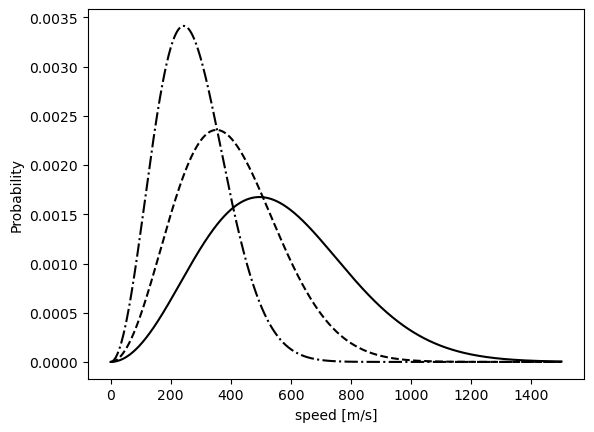

In [47]:
plt.plot(x_axis, neon_speed, linestyle="-", color="Black")
plt.plot(x_axis, argon_speed, linestyle="--", color="Black")
plt.plot(x_axis, krypton_speed, linestyle="-.", color="Black")
plt.xlabel("speed [m/s]")
plt.ylabel("Probability")
plt.show()

In the more complex version, you can set up a whole figure (aspects of which are described in the MatPlotLib documentation [here](https://matplotlib.org/stable/users/explain/axes/axes_intro.html)), with a bit more flexibility in making multiple plots with axes specific to each plot.

Here, the input to the plotting function also takes as arguments the x-axis values, the corresponding y-axis values, and then any other parameters like plot point `marker` or `linestyle` you want that's specific to that data.

```
ax.plot(x-values, y-values, param_name1 = param_value, param_name2 = param_value, ...)
```

Here is the more complex `plt.subplots` version of making a plot of the distribution function.

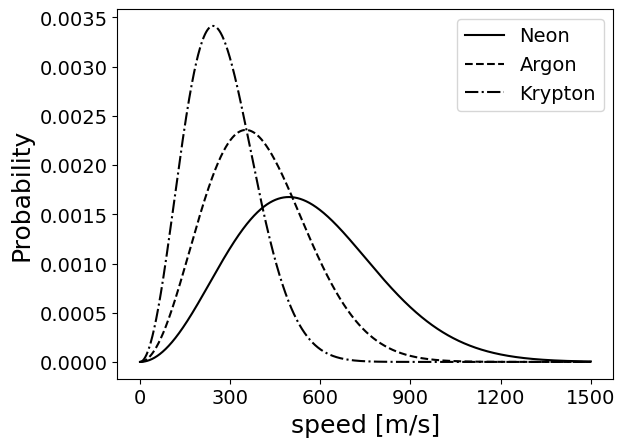

In [50]:
fig , ax = plt.subplots()
ax.plot(x_axis, neon_speed, linestyle="-", color="Black", label="Neon")
ax.plot(x_axis, argon_speed, linestyle="--", color="Black", label="Argon")
ax.plot(x_axis, krypton_speed, linestyle="-.", color="Black", label="Krypton")
ax.set_xlabel("speed [m/s]", fontsize="18")
ax.set_ylabel("Probability", fontsize="18")
ax.set_xticks(np.arange(0,1600,300))
ax.tick_params(labelsize = "14")
plt.legend(fontsize="14")
plt.show()

Note: The `np.arange()` function is similar to `np.linspace()` in that it creates a numpy array of equally spaced numbers within an interval. It's used here to create a list of ticks shown on the x-axis. 

In [52]:
print(np.arange(0,1600,300))

[   0  300  600  900 1200 1500]


# Calculating the Total Probability using a Probability Distribution

Now that we can see what the probability distribution looks like, let's make sure that it's normalized, so that the total probability equals 100% (e.g., that there's a 100% chance that a particle's speed is between 0 and $\infty$). 

The normalization constant is $\frac{1}{P_{Total}}$, and for a continuous variable with a domain of $-\infty$ to $\infty$,
$$
P_{Total} = \int_{-\infty}^{\infty}f(x)dx.
$$

So let's see what that integral is, assuming that the $f(x)$ function is the Maxwell Speed Distribution.

## New Python Skill: Integration

To integrate a function numerically, we can use the `scipy.integrate.quad()` function.
```
scipy.integrate.quad(function_name, min_int_var, max_int_var, args=(additional arguments to the function that you aren't integrating over))
```
This will print out a list containing the value of the integral as well as an estimate of the absolute error in the result. If we just want the integral, then we can add a `[0]` at the end to select the first item in the list that the function returns.

When using `function_name` in `scipy.integrate.quad()`, the integration variable should be the first argument listed in the argument list of `function_name`. Any other arguments to the function are listed using `args=()` 

Note: use `np.inf` to represent infinity as the maximum value of the integration variable.

In [ ]:
# Here's the full output
scipy.integrate.quad(speed_dist, 0, np.inf, args=(neonMW, 298))

(1.0000000000000009, 8.935144653703978e-09)

In [ ]:
# Here's just the value of the integral
scipy.integrate.quad(speed_dist, 0, np.inf, args=(neonMW, 298))[0]


1.0000000000000009

All those decimal places are not really necessary to show, given the small absolute error, so we can round all the values so that the numerical decimal value isn't shown anymore. 

Remember, you learned how to use the `round()` in the Introduction to Programming for Molecular Scientists module. 

In [105]:
neon_tot = scipy.integrate.quad(speed_dist, 0, np.inf, args=(neonMW, 298))[0]
print(neon_tot)
print(round(neon_tot,2))

1.0000000000000009
1.0


<h2 style="color:Purple;">Self Check 3</h2>

Now go ahead and calculate the total probability for the distributions for Argon and Krypton at 298 K.

Then round all the values so that the numerical decimal value isn't shown anymore.

Is the Maxwell Speed Distribution function $f(x)$ normalized already or will you need to redefine it with an explicit normalization constant? Explain how you know.

In [107]:
# Calculate total probability for the argon distribution here
argon_tot = scipy.integrate.quad(speed_dist, 0, np.inf, args=(argonMW, 298))[0]
print(argon_tot)
print(round(argon_tot,2))

1.0000000000000004
1.0


In [108]:
# Calculate total probability for the krypton distribution here
krypton_tot = scipy.integrate.quad(speed_dist, 0, np.inf, args=(kryptonMW, 298))[0]
print(krypton_tot)
print(round(krypton_tot,2))

1.0000000000000007
1.0


<h2 style="color:Purple;">Provide your answer to the question in the Markdown cell below:</h2>

Replace this text with your answer

## Visualizing the Probability over an Interval of the Distribution

We can visually represent the integration as "the area under the curve" by including the `ax.fill_between()` function that fills between the lines given by the first and second arguments to the function.

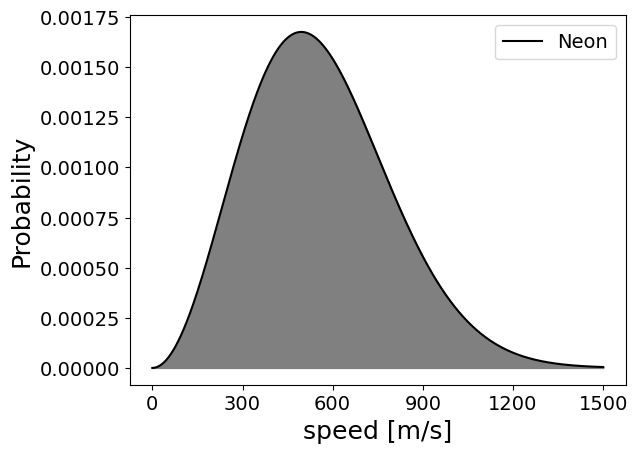

In [136]:
fig , ax = plt.subplots()
ax.plot(x_axis, neon_speed, linestyle="-", color="Black", label="Neon")
ax.set_xlabel("speed [m/s]", fontsize="18")
ax.set_ylabel("Probability", fontsize="18")
ax.set_xticks(np.arange(0,1600,300))
ax.tick_params(labelsize = "14")
ax.fill_between(x_axis, neon_speed, color="gray")
plt.legend(fontsize="14")
plt.show()

We can also visually represent the integration over an interval of the distribution. To do so, we need to specify just the specific interval on the x-axis as the first argument to the `ax.fill_between()` function. Then we can define the second argument to  `ax.fill_between()` as the y-axis values that correspond to the x-axis values over that interval.

Try it out below for the interval of $400 < x <600$.

To get the x-axis values, use the `np.argwhere()` function to select the indices of `x_axis` where the value of `x_axis` is greater than 400 and less than 600. Select the first index when $x>400$ and the last index when $x<600$.

In [131]:
# Select the first index using the [0] after np.argwhere(x_axis > 400)
print(np.argwhere(x_axis > 400)[0])

# Select the last index using the [-1] after np.argwhere(x_axis < 600)
print(np.argwhere(x_axis < 600)[-1])

[800]
[1199]


Then use `np.take()` to take just the value of the index (which is originally provided as an array) by using  `np.take(...,0)`.

In [132]:
x_gt400 = np.take(np.argwhere(x_axis > 400)[0],0)
x_lt600 = np.take(np.argwhere(x_axis < 600)[-1],0)

print(x_gt400)
print(x_lt600)

800
1199


Finally, create a list of x-axis values over that interval, and a list of y-axis values corresponding to those x-axis values. These will go into the `ax.fill_between()` function.

In [133]:
# If you aren't sure what fill_x_400_600 is, print it!
#print(x_axis[x_gt400:x_lt600])
fill_x_400_600 = x_axis[x_gt400:x_lt600]
plot_neon_400_600 = np.array(speed_dist(fill_x_400_600, neonMW, 298))

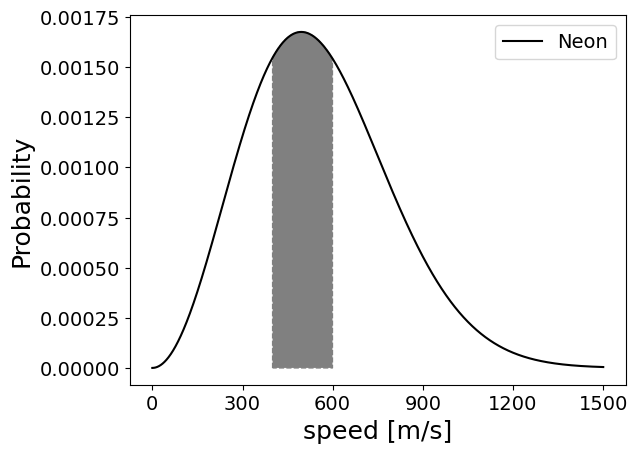

In [138]:
fig , ax = plt.subplots()
ax.plot(x_axis,neon_speed, linestyle="-", color="Black", label="Neon")
ax.set_xlabel("speed [m/s]", fontsize="18")
ax.set_ylabel("Probability", fontsize="18")
ax.set_xticks(np.arange(0,1600,300))
ax.tick_params(labelsize = "14")
ax.fill_between(fill_x_400_600,plot_neon_400_600, linestyle="--", color="gray")
plt.legend(fontsize="14")
plt.show()

## Calculating the Probability over an Interval of the Distribution

<h2 style="color:Purple;">Self Check 4</h2>

1.   Write a function called `prob_speed_range()` that will return the probability of finding an ideal gas particle within a range of speeds.
2.   Calculate the probability of finding a neon atom with a speed between 400 - 600 m/s at 298 K.
3.   Calculate the probability of finding an argon atom with a speed between 400 - 600 m/s at 298 K.
4.   Make a plot that allows you to visualize the integral (in task 3) over the 400 - 600 m/s range of speeds.

In [141]:
def prob_speed_range(mass,temperature,min,max):
  total = np.round(scipy.integrate.quad(speed_dist, min, max, args=(mass, temperature))[0],10)
  return print(round(total,3)*100,"%")

In [142]:
# Calculate  the probability of finding a neon atom with a speed between 400 - 600 m/s at 298 K here
prob_speed_range(neonMW,298,400,600)

32.6 %


In [143]:
# Calculate the probability of finding an argon atom with a speed between 400 - 600 m/s at 298 K here
prob_speed_range(argonMW,298,400,600)

34.0 %


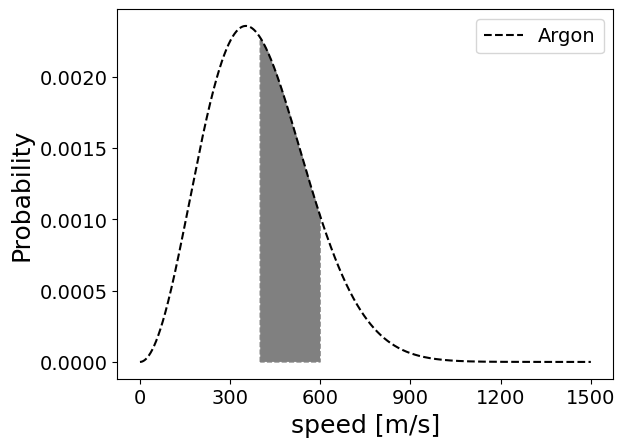

In [145]:
# Make a plot visualizing the integral of the argon speed distribution at 298 K between 400 - 600 m/s here

plot_argon_400_600 = np.array(speed_dist(fill_x_400_600, argonMW, 298))

fig , ax = plt.subplots()
ax.plot(x_axis,argon_speed, linestyle="--", color="Black", label="Argon")
ax.set_xlabel("speed [m/s]", fontsize="18")
ax.set_ylabel("Probability", fontsize="18")
ax.set_xticks(np.arange(0,1600,300))
ax.tick_params(labelsize = "14")
ax.fill_between(fill_x_400_600,plot_argon_400_600, linestyle="--", color="gray")
plt.legend(fontsize="14")
plt.show()

<h2 style="color:Red;">INSTRUCTOR NOTES</h2>
<h2 style="color:Red;">***</h2>
Depending on the length of the class session you are running, you may have to split up this activity into two class sessions. This is a good place to stop if you choose to do that.
<h2 style="color:Red;">***</h2>

# Characterizing a Probability Distribution

Probability distributions can be characterized by many different summary statistics.

One way to characterize the distribution is to calculate the **mode** of the distribution, which is the maximum value (i.e., the most probable value).
$$
\frac{P(x)}{dx} = 0
$$

Another way to characterize the distribution is by using the moments of the distribution.
* The **first moment** is the **average** of the distribution.  
* The square root of the **second moment** is the root mean square (**rms**) of the distribution.

Moments are calculated by taking the integral of the distribution multiplied by different orders of the sample variable itself.

First moment:
$$
<x> = \int_{-\infty}^{\infty} x^1 P(x)dx
$$

Second moment:
$$
<x^2> = \int_{-\infty}^{\infty} x^2 P(x)dx
$$

nth moment:
$$
<x^n> = \int_{-\infty}^{\infty} x^n P(x)dx
$$

## Calculate the Mode of the Distribution (i.e., most probable value)
## New Python Skill: Minimization

To calculate the mode, the max value of the distribution, use the `scipy.optimize.minimize()` function as shown below. 
```
scipy.optimize.minimize(funtion_name, initial_guess, optimization_method)
```
Here we will use speed=0 as the guess for the minimum value, and the [Nelder-Mead](https://docs.scipy.org/doc/scipy/reference/optimize.minimize-neldermead.html#optimize-minimize-neldermead) optimization method.

Note that we are calculating a minimum value, so we need to "flip" the function so that its max becomes a min. We do this by adding a negative sign to the `speed_dist()` function - this works, but in general you have to be careful when doing this depending on the function you're using.

In [265]:
# Try using scipy.optimize.minimize() without the flip
minimum=scipy.optimize.minimize(lambda speed: speed_dist(speed, neonMW, 298),0,method='Nelder-Mead').x[0]

In [266]:
# Note that this value of speed that's returned does NOT make sense according to the plots
print(minimum)

0.0


In [267]:
# Try using scipy.optimize.minimize() WITH the flip
minimum=scipy.optimize.minimize(lambda speed: -speed_dist(speed, neonMW, 298),0,method='Nelder-Mead').x[0]

In [268]:
# Note that this value of speed that's returned makes sense according to the plots
print(minimum)

495.52725000000066


*Aside*: The `.x[0]` ending is used to obtain the minimum value of the variable that the function is minimized with respect to. The result from the `scipy.optimize.minimize()` function contains a lot more information, but we just want to know what the minimum `x` value is, so we can specify: `scipy.optimize.minimize().x[0]` to get just the value of `x` from the minimization.

In [269]:
# Uncomment this section to check out how the results of the minimization look if you are interested.

#print("Full results of minimization:")
#print(scipy.optimize.minimize(lambda speed: -speed_dist(speed, argonMW, 298),0,method='Nelder-Mead'))
#print("Just the minimum x (as an item in an array):")
#print(scipy.optimize.minimize(lambda speed: -speed_dist(speed, argonMW, 298),0,method='Nelder-Mead').x)
#print("Just the minimum x value itself (not an item in an array):")
#print(scipy.optimize.minimize(lambda speed: -speed_dist(speed, argonMW, 298),0,method='Nelder-Mead').x[0])

## New Python Skill: Lambda Expressions
At this point, you might be wondering what that `lamda` term is doing in `scipy.optimize.minimize()`. A [lambda expression](https://docs.python.org/3/reference/expressions.html#lambda) is used to create an "anonymous" (i.e., unnamed) function. The unnamed function behaves like a function object defined with:
```
def <lambda>(parameters):
    return expression
```

Since the `speed_dist()` function we are using has multiple arguments, it wouldn't be clear to the `scipy.optimize.minimize()` which argument we want to minimize with respect to. So we can use a lambda expression to make an anonymous function that only depends on the argument we are minimizing with respect to (e.g., the `speed`), while still taking into account the other arguments for the original function (e.g., `mass` and `temperature`) that are used to determine the values of `speed_dist()`. In other words, the anonymous function is the function of `speed` we would get if we plugged in values for `mass` and `temperature` into `speed_dist()` first.

Now let's use a for loop (which you learned in the Introduction to Programming for Molecular Scientists module), to calculate the most probable speed `mp_speed` at 298 K for all three of the nobel gases we've looked at so far. 

In [270]:
# Define an array of 3 zeros
mp_speed = np.zeros(3)
print(mp_speed)

# Set the iteration variable, count
count = 0
for mass in (neonMW, argonMW, kryptonMW):
    print(mass)
    print(count)
    mp_speed[count] = round(scipy.optimize.minimize(lambda speed: -speed_dist(speed, mass, 298),0,method='Nelder-Mead').x[0],1)
    count+=1
print(mp_speed)

[0. 0. 0.]
0.02018
0
0.039948000000000004
1
0.083798
2
[495.5 352.2 243.2]


In [271]:
# Try printing just the most probable speed of neon
print(mp_speed[0])

495.5


<h2 style="color:Purple;">Self Check 5</h2>

Define a general function for calculating the most probable speed called `mp()` that takes in the `mass` and `temperature` as arguments. 
Verify that you get the same values for neon, argon, and krypton that you calculated above using the for loop.

In [272]:
# Define the function mp() here
def mp(mass, temperature):
    mp_value=scipy.optimize.minimize(lambda speed: -speed_dist(speed, mass, temperature),0,method='Nelder-Mead').x[0]
    return mp_value

# Print the most probable speeds for neon, argon, and krypton here
print(mp(neonMW,298))
print(mp(argonMW,298))
print(mp(kryptonMW,298))

495.52725000000066
352.19293750000054
243.17075000000034


## Calculate the First Moment
Write a function to calculate the first moment using a lambda expression within the `scipy.integrate.quad()` function.

In [277]:
def first_moment(mass, temperature):
    return scipy.integrate.quad(lambda speed: speed_dist(speed, mass, temperature)*speed, 0, np.inf)[0]

print(first_moment(neonMW,298))

559.1426473026053


## Calculate the Second Moment and Root Mean Square
Write a function to calculate the second moment using a lambda expression within the `scipy.integrate.quad()` function. Note that the units for the second moment are $\frac{m^2}{s^2}$, which aren't really that intuitive for our purposes. The square root of the second moment is more relevant to compare to other distribution characteristics.

In [289]:
# Let's try to write a function for the second moment based on what we did for the first moment
def second_moment(mass, temperature):
    return scipy.integrate.quad(lambda speed: speed_dist(speed, mass, temperature)*speed**2, 0, np.inf)[0]

print(second_moment(neonMW,298))

368320.91179385525


<h2 style="color:Purple;">Self Check 6</h2>

1. Write a function called `rms()` to calculate the root mean square speed for each distribution. The function should take in the `mass` and `temperature` as parameters.
2. Plot the most probable speed, average speed, and rms speed on the distribution for Argon at 298K. (The code to make a plot for Neon is provided so that you can see how to plot the specific points for most probable, average, and root mean square speeds. See how you can modify that code to make your plot for Argon.

In [280]:
# Define the function rms() here
def rms(mass, temperature):
    second_moment = scipy.integrate.quad(lambda speed: speed_dist(speed, mass, temperature)*speed**2, 0, np.inf)[0]
    return second_moment**(1/2)

In [282]:
rms(neonMW,298)

606.8944815977941

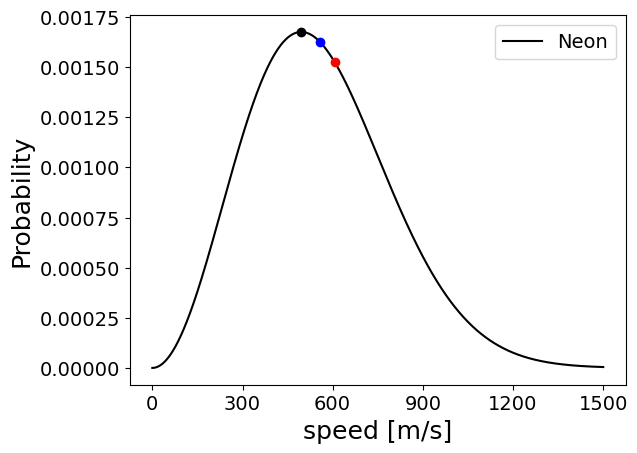

In [286]:
# Plot for Neon showing distribution characteristics
fig , ax = plt.subplots()
ax.plot(x_axis, neon_speed, linestyle="-", color="Black", label="Neon")
ax.plot(mp(neonMW,298), speed_dist(mp(neonMW,298),neonMW,298), marker="o",color="Black")
ax.plot(first_moment(neonMW,298), speed_dist(first_moment(neonMW,298),neonMW,298), marker="o",color="Blue")
ax.plot(rms(neonMW,298), speed_dist(rms(neonMW,298),neonMW,298), marker="o",color="Red")
ax.set_xlabel("speed [m/s]", fontsize="18")
ax.set_ylabel("Probability", fontsize="18")
ax.set_xticks(np.arange(0,1600,300))
ax.tick_params(labelsize = "14")
plt.legend(fontsize="14")
plt.show()

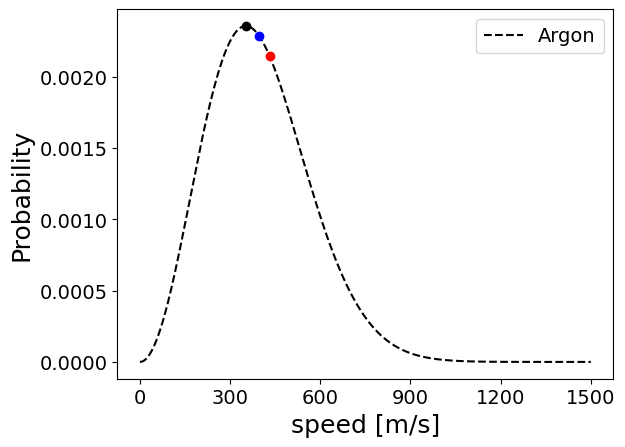

In [287]:
# Make your plot for Argon here
fig , ax = plt.subplots()
ax.plot(x_axis, argon_speed, linestyle="--", color="Black", label="Argon")
ax.plot(mp(argonMW,298), speed_dist(mp(argonMW,298),argonMW,298), marker="o",color="Black")
ax.plot(first_moment(argonMW,298), speed_dist(first_moment(argonMW,298),argonMW,298), marker="o",color="Blue")
ax.plot(rms(argonMW,298), speed_dist(rms(argonMW,298),argonMW,298), marker="o",color="Red")
ax.set_xlabel("speed [m/s]", fontsize="18")
ax.set_ylabel("Probability", fontsize="18")
ax.set_xticks(np.arange(0,1600,300))
ax.tick_params(labelsize = "14")
plt.legend(fontsize="14")
plt.show()

## Advanced Plotting using Subplots!

<h2 style="color:Red;">INSTRUCTOR NOTES</h2>
<h2 style="color:Red;">***</h2>
This challenge could be a take-home exercise. It's up to the instructor whether you want to show the "Answer Key" code I provided without the for loop. My students found it really hard to do this self check without having an example though, since it's using a lot of new aspects of Matplotlib. That said, some students were able to figure out how to complete the activity on their own without the example, but it was challenging for them. 
<h2 style="color:Red;">***</h2>

<h2 style="color:Purple;">Self Check 7 - Challenge!</h2>

Now go ahead and use what you know about for loops (and what you can glean from the example below) to make three subplots within your figure, each comparing Neon, Argon, and Krypton distributions at different temperatures: 100K, 298K, 500K. 

Hint: You can put a for loop inside the for loop shown below.

Column value = 0
temperature = 100
Column value = 1
temperature = 298
Column value = 2
temperature = 500


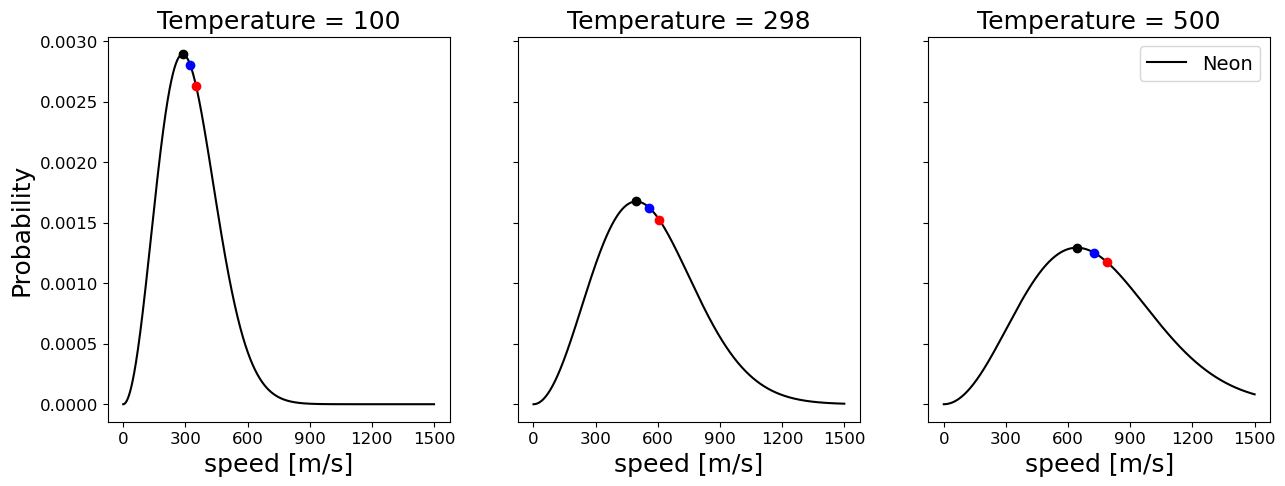

In [290]:
# Example Subplots

# Set up the mass as an array - here it has 1 item, but you could add more!
mass = [neonMW]
# Set up temperature as an array - here it has 3 items
temperature = [100,298,500]
# Set up the linestyle as an array - we've used "-" for neon, "--" for argon, and ".-" for krypton
linestyle = ["-"]
# Set up the label for the plot as an array
label = ["Neon"]

fig , ax = plt.subplots(ncols=3, figsize=(15,5), sharey=True)
for col in range(3):
    print("Column value = {}".format(col))
    print("temperature = {}".format(temperature[col]))
    ax[col].plot(x_axis, speed_dist(x_axis,mass[0],temperature[col]), linestyle=linestyle[0], color="Black", label=label[0])
    ax[col].plot(mp(mass[0],temperature[col]), speed_dist(mp(mass[0],temperature[col]),mass[0],temperature[col]), marker="o",color="Black")
    ax[col].plot(first_moment(mass[0],temperature[col]), speed_dist(first_moment(mass[0],temperature[col]),mass[0],temperature[col]), marker="o",color="Blue")
    ax[col].plot(rms(mass[0],temperature[col]), speed_dist(rms(mass[0],temperature[col]),mass[0],temperature[col]), marker="o",color="Red")
    ax[col].set_title("Temperature = "+str(temperature[col]), fontsize="18")
    ax[col].set_xlabel("speed [m/s]", fontsize="18")
    ax[col].set_xticks(np.arange(0,1600,300))
    ax[col].tick_params(labelsize = "12")
    if col == 0:
        ax[col].set_ylabel("Probability", fontsize="18")

plt.legend(fontsize="14")
plt.show()

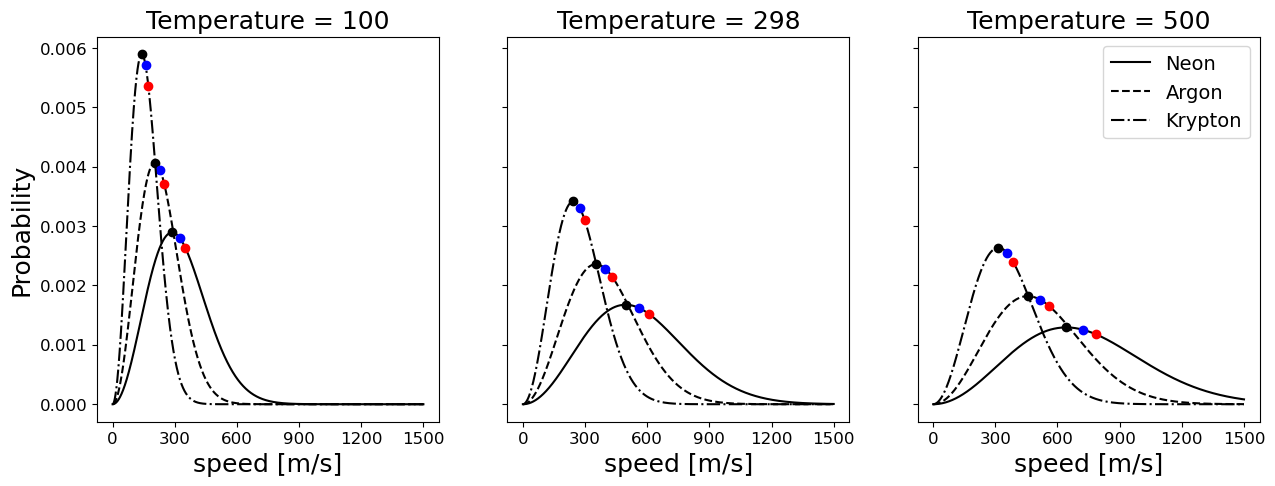

In [62]:
# Put your own answer here:
mass = [neonMW, argonMW, kryptonMW]
temperature = [100,298,500]
linestyle = ["-","--","-."]
label = ["Neon","Argon","Krypton"]

fig , ax = plt.subplots(ncols=3, figsize=(15,5), sharey=True)
for col in range(3):
    for i in range(3):
        #print(i)
        ax[col].plot(x_axis, speed_dist(x_axis,mass[i],temperature[col]), linestyle=linestyle[i], color="Black", label=label[i])
        ax[col].plot(mp(mass[i],temperature[col]), speed_dist(mp(mass[i],temperature[col]),mass[i],temperature[col]), marker="o",color="Black")
        ax[col].plot(first_moment(mass[i],temperature[col]), speed_dist(first_moment(mass[i],temperature[col]),mass[i],temperature[col]), marker="o",color="Blue")
        ax[col].plot(rms(mass[i],temperature[col]), speed_dist(rms(mass[i],temperature[col]),mass[i],temperature[col]), marker="o",color="Red")
    ax[col].set_title("Temperature = "+str(temperature[col]), fontsize="18")
    ax[col].set_xlabel("speed [m/s]", fontsize="18")
    ax[col].set_xticks(np.arange(0,1600,300))
    ax[col].tick_params(labelsize = "12")
    if col == 0:
        ax[col].set_ylabel("Probability", fontsize="18")

plt.legend(fontsize="14")
plt.show()

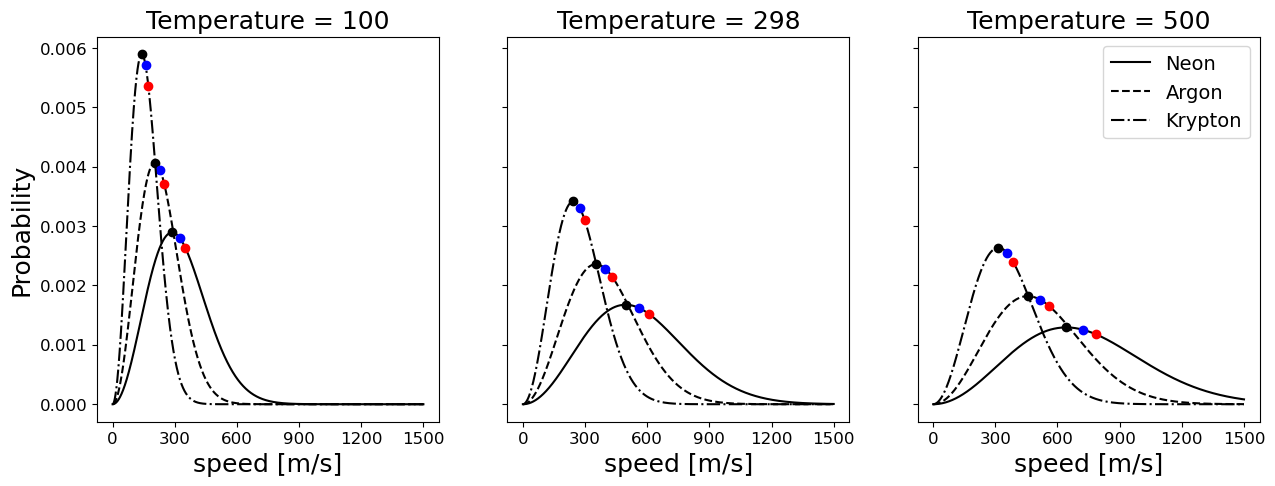

In [293]:
# Answer key for reference without for loop: 
# This plot is what you are trying to make - but who wants to type all this out!?
# Put it into a for loop to make it more concise!

fig , ax = plt.subplots(ncols=3, figsize=(15,5), sharey=True)

ax[0].plot(x_axis, speed_dist(x_axis,neonMW,100), linestyle="-", color="Black", label="Neon")
ax[0].plot(mp(neonMW,100), speed_dist(mp(neonMW,100),neonMW,100), marker="o",color="Black")
ax[0].plot(first_moment(neonMW,100), speed_dist(first_moment(neonMW,100),neonMW,100), marker="o",color="Blue")
ax[0].plot(rms(neonMW,100), speed_dist(rms(neonMW,100),neonMW,100), marker="o",color="Red")

ax[0].plot(x_axis, speed_dist(x_axis,argonMW,100), linestyle="--", color="Black", label="Argon")
ax[0].plot(mp(argonMW,100), speed_dist(mp(argonMW,100),argonMW,100), marker="o",color="Black")
ax[0].plot(first_moment(argonMW,100), speed_dist(first_moment(argonMW,100),argonMW,100), marker="o",color="Blue")
ax[0].plot(rms(argonMW,100), speed_dist(rms(argonMW,100),argonMW,100), marker="o",color="Red")

ax[0].plot(x_axis, speed_dist(x_axis,kryptonMW,100), linestyle="-.", color="Black", label="Krypton")
ax[0].plot(mp(kryptonMW,100), speed_dist(mp(kryptonMW,100),kryptonMW,100), marker="o",color="Black")
ax[0].plot(first_moment(kryptonMW,100), speed_dist(first_moment(kryptonMW,100),kryptonMW,100), marker="o",color="Blue")
ax[0].plot(rms(kryptonMW,100), speed_dist(rms(kryptonMW,100),kryptonMW,100), marker="o",color="Red")

ax[0].set_title("Temperature = "+str(100), fontsize="18")
ax[0].set_xlabel("speed [m/s]", fontsize="18")
ax[0].set_xticks(np.arange(0,1600,300))
ax[0].tick_params(labelsize = "12")



ax[1].plot(x_axis, speed_dist(x_axis,neonMW,298), linestyle="-", color="Black", label="Neon")
ax[1].plot(mp(neonMW,298), speed_dist(mp(neonMW,298),neonMW,298), marker="o",color="Black")
ax[1].plot(first_moment(neonMW,298), speed_dist(first_moment(neonMW,298),neonMW,298), marker="o",color="Blue")
ax[1].plot(rms(neonMW,298), speed_dist(rms(neonMW,298),neonMW,298), marker="o",color="Red")

ax[1].plot(x_axis, speed_dist(x_axis,argonMW,298), linestyle="--", color="Black", label="Argon")
ax[1].plot(mp(argonMW,298), speed_dist(mp(argonMW,298),argonMW,298), marker="o",color="Black")
ax[1].plot(first_moment(argonMW,298), speed_dist(first_moment(argonMW,298),argonMW,298), marker="o",color="Blue")
ax[1].plot(rms(argonMW,298), speed_dist(rms(argonMW,298),argonMW,298), marker="o",color="Red")

ax[1].plot(x_axis, speed_dist(x_axis,kryptonMW,298), linestyle="-.", color="Black", label="Krypton")
ax[1].plot(mp(kryptonMW,298), speed_dist(mp(kryptonMW,298),kryptonMW,298), marker="o",color="Black")
ax[1].plot(first_moment(kryptonMW,298), speed_dist(first_moment(kryptonMW,298),kryptonMW,298), marker="o",color="Blue")
ax[1].plot(rms(kryptonMW,298), speed_dist(rms(kryptonMW,298),kryptonMW,298), marker="o",color="Red")

ax[1].set_title("Temperature = "+str(298), fontsize="18")
ax[1].set_xlabel("speed [m/s]", fontsize="18")
ax[1].set_xticks(np.arange(0,1600,300))
ax[1].tick_params(labelsize = "12")



ax[2].plot(x_axis, speed_dist(x_axis,neonMW,500), linestyle="-", color="Black", label="Neon")
ax[2].plot(mp(neonMW,500), speed_dist(mp(neonMW,500),neonMW,500), marker="o",color="Black")
ax[2].plot(first_moment(neonMW,500), speed_dist(first_moment(neonMW,500),neonMW,500), marker="o",color="Blue")
ax[2].plot(rms(neonMW,500), speed_dist(rms(neonMW,500),neonMW,500), marker="o",color="Red")

ax[2].plot(x_axis, speed_dist(x_axis,argonMW,500), linestyle="--", color="Black", label="Argon")
ax[2].plot(mp(argonMW,500), speed_dist(mp(argonMW,500),argonMW,500), marker="o",color="Black")
ax[2].plot(first_moment(argonMW,500), speed_dist(first_moment(argonMW,500),argonMW,500), marker="o",color="Blue")
ax[2].plot(rms(argonMW,500), speed_dist(rms(argonMW,500),argonMW,500), marker="o",color="Red")

ax[2].plot(x_axis, speed_dist(x_axis,kryptonMW,500), linestyle="-.", color="Black", label="Krypton")
ax[2].plot(mp(kryptonMW,500), speed_dist(mp(kryptonMW,500),kryptonMW,500), marker="o",color="Black")
ax[2].plot(first_moment(kryptonMW,500), speed_dist(first_moment(kryptonMW,500),kryptonMW,500), marker="o",color="Blue")
ax[2].plot(rms(kryptonMW,500), speed_dist(rms(kryptonMW,500),kryptonMW,500), marker="o",color="Red")

ax[2].set_title("Temperature = "+str(500), fontsize="18")
ax[2].set_xlabel("speed [m/s]", fontsize="18")
ax[2].set_xticks(np.arange(0,1600,300))
ax[2].tick_params(labelsize = "12")


ax[0].set_ylabel("Probability", fontsize="18")

plt.legend(fontsize="14")
plt.show()